# Practica 6 clasificacion con KNN

Se clasifica el volumen de trafico como bajo o alto usando datos del clima

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

path = "../data/procesed/metro.csv"
metro = pd.read_csv(path)
metro.head()

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


Datos para el modelo

Trafico bajo es menor a 3000 vehiculos y trafico alto es de 3000 en adelante
Se deja un registro por fecha y hora para evitar repetirlo entre entrenamiento y prueba

In [2]:
columnas = ["temp", "rain_1h", "snow_1h", "clouds_all"]
datos = metro.drop_duplicates(subset="date_time")
datos = datos.dropna(subset=columnas + ["traffic_volume"])
x = datos[columnas]
y = (datos["traffic_volume"] >= 3000).map({False: "bajo", True: "alto"})

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

y.value_counts()

traffic_volume
alto    22753
bajo    17822
Name: count, dtype: int64

Modelo KNN

Se escalan las variables con los datos de entrenamiento y se usan 5 vecinos

In [3]:
modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo.fit(x_train, y_train)

y_pred = modelo.predict(x_test)

Evaluacion

Se mide la exactitud y se revisan precision, recall y f1 por clase con los datos de prueba

In [4]:
exactitud = accuracy_score(y_test, y_pred)
print("exactitud", round(exactitud, 3))
print(classification_report(y_test, y_pred, zero_division=0))

exactitud 0.582
              precision    recall  f1-score   support

        alto       0.62      0.65      0.64      4551
        bajo       0.53      0.49      0.51      3564

    accuracy                           0.58      8115
   macro avg       0.57      0.57      0.57      8115
weighted avg       0.58      0.58      0.58      8115



Matriz de confusion

La diagonal muestra los aciertos y las otras celdas muestran los errores

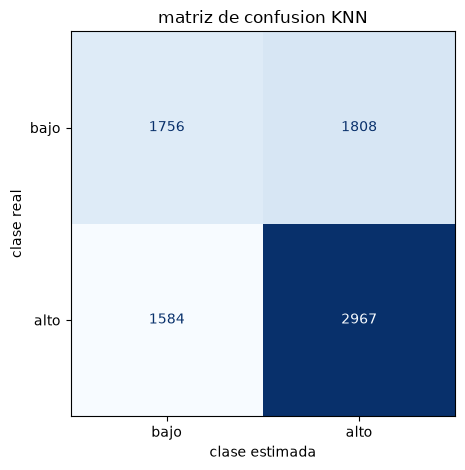

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["bajo", "alto"], cmap="Blues", colorbar=False
)
plt.xlabel("clase estimada")
plt.ylabel("clase real")
plt.title("matriz de confusion KNN")
plt.tight_layout()
plt.show()

El modelo obtuvo una exactitud de 58,2% en los datos de prueba
Las variables del clima tienen poca capacidad para distinguir entre trafico bajo y alto con este modelo